# Contextuality and inductive bias in quantum machine learning — a reproduction walkthrough

**Paper.** J. Bowles, V. J. Wright, M. Farkas, N. Killoran, M. Schuld, *Contextuality and inductive bias in quantum machine learning*, arXiv:2302.01365 (2023). Author code: [XanaduAI/Contextual-ML](https://github.com/XanaduAI/Contextual-ML). It has no license, so it was used as a reference only; this repository reimplements everything in PyTorch.

**What this notebook is.** A self-contained scientific argument. It states the paper's claim, shows the evidence for and against it, tests alternative explanations, and ends with a claim-by-claim verdict. Results come from two sources, always labelled:

- **live**: computed in this notebook. Everything live runs on CPU in about 6 minutes.
- **stored**: loaded from the full sweeps (hundreds of runs, about 10 CPU-hours). They are kept as compact curated files in `results/`, and `LOG.md` records their provenance.

Contents:
1. Problem statement and paper claim
2. Data, splits, metrics and evaluation protocol
3. Minimum mathematics
4. Known-answer sanity checks
5. Model walkthrough
6. Small live experiment
7. Headline reproduction result
8. Fair baseline comparison
9. Controls and ablations
10. Robustness and uncertainty
11. Photonic (MerLin) assessment
12. Claim-level conclusion and limitations

In [1]:
# Setup: paths, imports from lib/, and every scientifically important setting.
import csv
import json
import math
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy import stats

PAPER_DIR = Path.cwd().resolve()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError(f"Run this notebook from papers/contextuality_inductive_bias, not {PAPER_DIR}")
sys.path.insert(0, str(PAPER_DIR.parent))          # makes `contextuality_inductive_bias.lib` importable
sys.path.insert(0, str(PAPER_DIR / "utils"))      # analysis helpers (witness LP, sweep naming)
RESULTS = PAPER_DIR / "results"

from contextuality_inductive_bias.lib import data as data_lib
from contextuality_inductive_bias.lib import metrics as metrics_lib
from contextuality_inductive_bias.lib import rps_game, theory
from contextuality_inductive_bias.lib.runner import build_model
from contextuality_inductive_bias.lib.training import train

torch.set_num_threads(4)
DTYPE = torch.float64
DEVICE = torch.device("cpu")
CFG = json.loads((PAPER_DIR / "configs" / "defaults.json").read_text())
CFG["data"]["validation"]["enabled"] = True   # held-out split (data seed 201) used only for model selection
TIMER_START = time.perf_counter()

# One colour per model family, used in every figure.
COLORS = {
    "quantum biased": "#2a78d6", "quantum generic": "#8a8f98", "surrogate": "#1baf7a",
    "B2": "#eb6834", "B3": "#c9a227", "B4": "#9c6644", "B5": "#6c3483", "photonic": "#4a3aa7",
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("torch", torch.__version__, "| CPU threads", torch.get_num_threads(), "| paper dir", PAPER_DIR.name)

torch 2.12.1 | CPU threads 4 | paper dir contextuality_inductive_bias


## 1. Problem statement and paper claim

**Setting.** Three binary prediction tasks share one input $x$. The labels $Y_k\in\{\pm1\}$, $k=1,2,3$, obey a *zero-sum* constraint on their conditional expectations:

$$\mathbb E[Y_1\mid x]+\mathbb E[Y_2\mid x]+\mathbb E[Y_3\mid x]=0\quad\text{for every }x .$$

The paper treats this constraint as an *operational equivalence* in the sense of Spekkens' generalised contextuality. It proves that **noncontextual** models encoding the constraint cannot express every behaviour the constraint allows (Lemma 4.1, Theorem 4.1). Quantum models can encode the constraint *and* be contextual, so the constraint is offered as an inductive bias that favours quantum models.

**Paper's empirical claims (Sec. 8, Figs. 8, 9, 11), on a three-player rock-paper-scissors (RPS) task:**

| ID | Claim |
|---|---|
| C7 | A 3-qubit model that encodes the bias reaches a lower test KL than a generic quantum model and than Fourier "classical surrogates" (Fig. 8). |
| C8 | The surrogates beat the generic quantum model. |
| C10 | L2 regularisation curbs surrogate overfitting but does not reach the biased model (Figs. 9, 11). |
| C11 | The gap comes from the encoded bias, which "cannot be easily encoded" in the surrogates or classical models. |

**Falsifiable research question.** *Does the biased quantum model generalise better (lower test KL) than classical alternatives that receive the same data, the same training budget and the same tuning budget? If it does, is the reason the bias, or contextuality?*

Evidence that would **weaken** the claim:
- (a) The paper's figure depends on an evaluation detail rather than on the models.
- (b) An equally tuned surrogate matches or beats the biased model.
- (c) A *classical* model with the same bias hard-coded matches or beats it.
- (d) A provably *noncontextual* model with the bias performs as well as one that can be contextual.

All four tests are run below.

## 2. Data, splits, metrics and evaluation protocol

**Inputs.** Each input is a 3×3 strategy matrix $s$: row $k$ gives player $k$'s probabilities of playing Rock, Paper or Scissors. It is compressed to six features (paper Eq. (93)) and multiplied by $\pi/2$. **Labels.** The $Y_k$ are win (0) or lose (1) outcomes of each player, sampled from the exact win probabilities $P_k(x)=P(Y_k=+1\mid x)$. Because the payoffs are zero-sum, $\sum_k P_k = 3/2$.

| Split | Source | Size | Use |
|---|---|---:|---|
| train | author arrays `Xdata.npy`, `Ydata.npy` (SHA-256 checked); identical to the paper's generator with seed 999 | 1500 | fitting |
| validation | generated, data seed 201, labelled | 1500 | **only** hyperparameter selection and early stopping (our addition) |
| test | generated, seed 2302, exact $P_k$ | 10000 | reporting only; never used for selection |

**Metric (Eqs. (102)-(103)).** The average test KL divergence between the true and the predicted Bernoulli distributions of each task. Lower is better:

$$\mathrm{KL}=\frac{1}{3N}\sum_{i=1}^{N}\sum_{k=1}^{3} \Big[P_k\log\tfrac{P_k}{\hat P_k}+(1-P_k)\log\tfrac{1-P_k}{1-\hat P_k}\Big],\qquad \hat P_k=\tfrac{1+\mathbb E_\theta[Y_k\mid x]}{2}.$$

Training minimises the mean label NLL (Eq. (101)) with full-batch steps.

In [2]:
train_split, validation_split, test_split = (data_lib.load_split(CFG, s) for s in ("train", "validation", "test"))
for split in (train_split, validation_split, test_split):
    p = split.provenance
    print(f"{split.name:<10} n={split.size:<6} source={p['source']:<9} seed={p.get('seed', '-')!s:<5} "
          f"input scale={split.input_scale:.4f}  sha256={p['array_sha256'][:12]}")

true_sum = test_split.win_probabilities.sum(dim=1)
print(f"\nZero-sum check on the true test behaviours: max |sum_k P_k - 3/2| = {float((true_sum - 1.5).abs().max()):.1e}")
print(f"Train label balance (fraction of 'win'): {float((train_split.labels == 0).double().mean()):.3f}")

train      n=1500   source=author    seed=-     input scale=1.5708  sha256=0769fd0e1ad4
validation n=1500   source=generated seed=201   input scale=1.5708  sha256=3e01d12317b9
test       n=10000  source=generated seed=2302  input scale=1.5708  sha256=35c020047c00

Zero-sum check on the true test behaviours: max |sum_k P_k - 3/2| = 2.2e-16
Train label balance (fraction of 'win'): 0.507


**Evaluation protocols (discrepancy D12).** The paper text applies the $\pi/2$ scaling to *all* inputs. The author notebook applies it to the training inputs but evaluates the test KL on **unscaled** test inputs. A third-party fork of the author repository found the same issue. We therefore run three pre-declared protocols:

In [3]:
print("protocol   train scale   test scale   role")
roles = {"paper": "consistent with the paper text; used for every verdict",
         "code": "the author notebook's evaluation; reproduces the published figure",
         "fork": "unscaled on both sides; a sanity check"}
for name, scales in data_lib.PROTOCOLS.items():
    print(f"{name:<9} {scales['train']:>10.4f} {scales['test']:>12.4f}   {roles[name]}")

protocol   train scale   test scale   role
paper         1.5708       1.5708   consistent with the paper text; used for every verdict
code          1.5708       1.0000   the author notebook's evaluation; reproduces the published figure
fork          1.0000       1.0000   unscaled on both sides; a sanity check


**Where do the test behaviours lie?** Each true behaviour $(P_1,P_2,P_3)$ lies on a hexagon: the zero-sum plane $\sum_k P_k=3/2$ inside the unit cube. The hexagon's vertices are the six extremal behaviours. Theorem 4.1 is about the shrunken hexagon $V_\eta$, the copy scaled by $\eta$ about the centre $(\tfrac12,\tfrac12,\tfrac12)$. On this plane, $V_\eta=\{P:\max_k|P_k-\tfrac12|\le \eta/2\}$. So $d(P)=\max_k|P_k-\tfrac12|$ measures how far a behaviour is from the centre, and a behaviour lies outside $V_{2/3}$ exactly when $d>1/3$. Only behaviours outside $V_{2/3}$ are beyond the reach of noncontextual biased models.

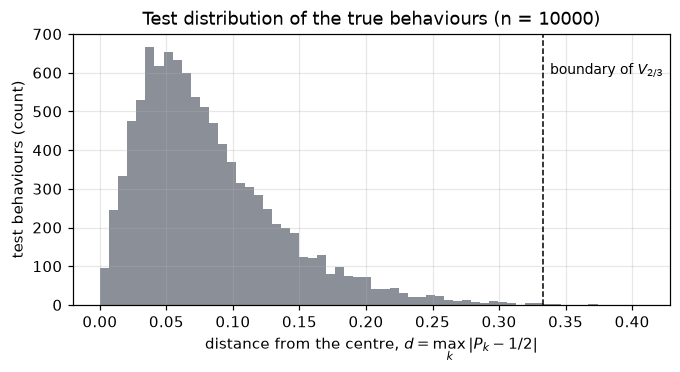

Fraction of test behaviours outside V_2/3: 0.120%


In [4]:
distance = (test_split.win_probabilities - 0.5).abs().max(dim=1).values.numpy()
outside = float((distance > 1 / 3).mean())
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(distance, bins=60, color="#8a8f98")
ax.axvline(1 / 3, color="k", ls="--", lw=1)
ax.text(1 / 3 + 0.005, ax.get_ylim()[1] * 0.85, "boundary of $V_{2/3}$", fontsize=9)
ax.set_xlabel(r"distance from the centre, $d=\max_k |P_k - 1/2|$")
ax.set_ylabel("test behaviours (count)")
ax.set_title("Test distribution of the true behaviours (n = 10000)")
plt.show()
print(f"Fraction of test behaviours outside V_2/3: {outside:.3%}")

**Observation.** Almost all true behaviours sit close to the centre of the hexagon; only about 0.1% lie outside $V_{2/3}$. **Inference.** Theorem 4.1 limits noncontextual biased models only outside $V_{2/3}$. On this test distribution it can therefore explain at most a tiny part of any performance gap. **Claim impact.** This does not touch C7 directly, but it already makes "contextuality explains the gap" (one reading of C11) unlikely. Sections 9 and 11 test it directly.

## 3. Minimum mathematics

**Contextuality in one paragraph.** A trained multi-task model defines an operational scenario:
- *preparations* are the inputs $x$;
- *effects* are "read label $y$ of task $k$".

The zero-sum constraint makes the three effects $E^1_+,E^2_+,E^3_+$ operationally equivalent to a fixed mixture, whatever the input. A *noncontextual* ontological model must represent operationally equivalent procedures identically. For the six inputs $s_1,\dots,s_6$ whose behaviours $u_j(\eta)$ are the vertices of $V_\eta$, this forces (Lemma 4.1, paper Eq. (44))

$$P(E^1_+\mid s_1)+P(E^2_+\mid s_3)+P(E^3_+\mid s_5)\;\le\;\tfrac52 .$$

On the vertices of $V_\eta$, the left-hand side equals $\tfrac32(\eta+1)$, so noncontextual biased models cannot contain $V_\eta$ for $\eta>2/3$ (Theorem 4.1).

**Biased quantum model (Fig. 7).**
- Three qubits start in a state with $\langle Z_1+Z_2+Z_3\rangle=0$.
- The data-encoding and trainable generators all commute with $H=Z_1+Z_2+Z_3$, so $\langle H\rangle=0$ is preserved.
- The model outputs $\mathbb E[Y_k\mid x]=\langle Z_k\rangle$, and therefore satisfies the constraint *exactly*, for every $x$ and every $\theta$.
- There are $L$ re-uploading layers and $B$ trainable blocks: 55 parameters at $L=1$ and 91 at $L=2$.

**Generic quantum model (Fig. 10).** General single-qubit rotations and CNOTs, with no constraint: 54 parameters at $L=1$ and 90 at $L=2$.

**Classical surrogate (Sec. 8.3).** Every quantum output is a truncated Fourier series in the encoded inputs, with frequency spectrum $\Omega_L$. The surrogate fits that series linearly and clips the output with HardTanh:
- $L=1$: 4374 parameters;
- $L=2$: 93750 parameters.

Its function class *contains* the quantum models' class, so any advantage of the quantum model must come from inductive bias, not expressivity.

In [5]:
def make_model(kind, seed, **model_overrides):
    # Same seeding as lib/runner.py: global torch RNG (MLPs, MerLin) and a generator (quantum, surrogate).
    torch.manual_seed(seed)
    model_cfg = dict(CFG["model"], kind=kind, **model_overrides)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return build_model(model_cfg, torch.Generator().manual_seed(seed), DTYPE, DEVICE)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

## 4. Known-answer sanity checks

Each check below has a known exact answer. The full test suite (`tests/`, 134 tests) covers more, for example agreement of the simulator with PennyLane and of torch Adam with optax to 1e-12.

In [6]:
# (a) The six deterministic profiles of Sec. 5.2 give exactly the six hexagon vertices.
profiles = np.stack([rps_game.deterministic_strategy(p) for p in rps_game.EXTREMAL_PROFILES])
vertex_error = np.abs(rps_game.win_probabilities(profiles) - rps_game.HEXAGON_VERTICES).max()
print(f"(a) extremal profiles {rps_game.EXTREMAL_PROFILES} -> hexagon vertices, max error {vertex_error:.1e}")

# (b) Lemma 4.1 and Theorem 4.1 as linear programs over noncontextual decompositions.
lemma = theory.max_lemma_lhs(with_preparation_equivalence=True)["optimum"]
lemma_without = theory.max_lemma_lhs(with_preparation_equivalence=False)["optimum"]
eta_max = theory.max_noncontextual_eta()["eta_max"]
print(f"(b) max Lemma 4.1 LHS = {lemma:.6f} (paper 5/2); without the preparation equivalence {lemma_without:.6f} (3)")
print(f"    largest eta with a noncontextual model = {eta_max:.6f} (paper 2/3); LHS at eta=2/3: {theory.lemma_lhs_for_eta(2/3):.6f}")
assert abs(lemma - 2.5) < 1e-9 and abs(lemma_without - 3) < 1e-9 and abs(eta_max - 2 / 3) < 1e-9

(a) extremal profiles ('RSS', 'SRS', 'RPR', 'RRP', 'PPS', 'SPP') -> hexagon vertices, max error 0.0e+00
(b) max Lemma 4.1 LHS = 2.500000 (paper 5/2); without the preparation equivalence 3.000000 (3)
    largest eta with a noncontextual model = 0.666667 (paper 2/3); LHS at eta=2/3: 2.500000


In [7]:
# (c) The biased ansatz conserves the zero-sum constraint for random parameters; the generic ansatz does not.
x = test_split.features[:2000]
for kind, extra in (("biased_quantum", {"layers": 1}), ("biased_quantum", {"layers": 2}),
                    ("generic_quantum", {"layers": 1}), ("generic_quantum", {"layers": 2})):
    worst = max(metrics_lib.zero_sum_violation(make_model(kind, seed, **extra)(x).detach()) for seed in range(3))
    print(f"(c) {kind:<16} L={extra['layers']}: max |sum_k E[Y_k|x]| over 3 random inits x 2000 inputs = {worst:.1e}")

(c) biased_quantum   L=1: max |sum_k E[Y_k|x]| over 3 random inits x 2000 inputs = 1.7e-15
(c) biased_quantum   L=2: max |sum_k E[Y_k|x]| over 3 random inits x 2000 inputs = 2.5e-15
(c) generic_quantum  L=1: max |sum_k E[Y_k|x]| over 3 random inits x 2000 inputs = 1.5e+00
(c) generic_quantum  L=2: max |sum_k E[Y_k|x]| over 3 random inits x 2000 inputs = 1.7e+00


**Observation.** All the exact quantities come out as published:
- the six extremal behaviours;
- the bound 5/2, which becomes 3 without the equivalence;
- the threshold 2/3.

The biased ansatz conserves the constraint to machine precision; the generic one violates it by $O(1)$.

**Claim impact.** The theory claims (C1-C6) are **reproduced exactly**. These are component checks, not a reproduction of the empirical claim.

## 5. Model walkthrough

Every model maps the six features to three expectations $\mathbb E[Y_k\mid x]\in[-1,1]$. The table lists every model used below:
- the paper's models;
- the fair baselines B2-B5 added in this reproduction (section 8);
- the MerLin photonic adaptation (section 11).

For each, it reports the parameter count and whether the zero-sum constraint holds by construction. It is computed live from fresh initialisations.

In [8]:
MODEL_ZOO = [
    ("quantum biased L=1", "biased_quantum", {"layers": 1}, "paper model"),
    ("quantum biased L=2", "biased_quantum", {"layers": 2}, "paper model (Fig. 8 setting)"),
    ("quantum generic L=1", "generic_quantum", {"layers": 1}, "paper baseline"),
    ("quantum generic L=2", "generic_quantum", {"layers": 2}, "paper baseline"),
    ("surrogate L=1 (B0)", "surrogate", {"spectrum": 1}, "paper baseline"),
    ("surrogate L=2", "surrogate", {"spectrum": 2}, "paper baseline"),
    ("B2 bias-encoded Fourier L=1", "bias_fourier", {"spectrum": 1}, "added: softmax over the 6 hexagon vertices"),
    ("B3 bias-encoded MLP h=7", "mlp_biased", {"hidden": 7}, "added: MLP with vertex softmax"),
    ("B4 unbiased MLP h=9", "mlp_unbiased", {"hidden": 9}, "added: MLP with 3 sigmoids"),
    ("B5 quadratic", "quadratic", {}, "added: degree-2 polynomial (ceiling)"),
    ("photonic vertex N=2", "photonic_merlin", {"readout": "vertex"}, "MerLin adaptation"),
    ("photonic group N=2", "photonic_merlin", {"readout": "group"}, "MerLin adaptation, noncontextual"),
    ("photonic unbiased N=2", "photonic_merlin", {"readout": "unbiased"}, "MerLin adaptation, no bias"),
]
print(f"{'model':<30} {'params':>7} {'max |sum_k E|':>14}  role")
x_small = test_split.features[:500]
for name, kind, extra, role in MODEL_ZOO:
    model = make_model(kind, 0, **extra)
    with torch.no_grad():
        violation = "(not run)" if name == "surrogate L=2" else f"{metrics_lib.zero_sum_violation(model(x_small)):.1e}"
    print(f"{name:<30} {n_params(model):>7} {violation:>14}  {role}")

model                           params  max |sum_k E|  role
quantum biased L=1                  55        1.7e-15  paper model
quantum biased L=2                  91        2.3e-15  paper model (Fig. 8 setting)
quantum generic L=1                 54        1.5e+00  paper baseline
quantum generic L=2                 90        1.3e+00  paper baseline
surrogate L=1 (B0)                4374        4.4e-02  paper baseline
surrogate L=2                    93750      (not run)  paper baseline
B2 bias-encoded Fourier L=1       8748        6.7e-16  added: softmax over the 6 hexagon vertices
B3 bias-encoded MLP h=7             97        1.0e-15  added: MLP with vertex softmax
B4 unbiased MLP h=9                 93        4.5e-01  added: MLP with 3 sigmoids
B5 quadratic                        84        1.2e+00  added: degree-2 polynomial (ceiling)
photonic vertex N=2                 90        1.1e-15  MerLin adaptation


photonic group N=2                  90        8.9e-16  MerLin adaptation, noncontextual


photonic unbiased N=2              108        6.5e-02  MerLin adaptation, no bias


The surrogate L=2 forward pass is skipped here because of memory: it has 31250 features per sample. Sections 7 and 8 use its stored runs.

**How the bias is encoded in each family:**
- **Quantum biased:** generators commute with $Z_1+Z_2+Z_3$.
- **B2 and B3:** the output is a convex combination (softmax weights) of the six hexagon vertices, so it lies on the zero-sum hexagon *by construction*. B2 uses the surrogate's Fourier features; B3 uses a 7-unit tanh MLP.
- **Photonic vertex and group:** photon-number conservation in passive linear optics (section 11).
- **No bias:** the generic quantum model, the surrogates, B4 and B5 can violate the constraint.

Parameter counts are matched at about 91 for the quantum, photonic, B3, B4 and B5 models. B2 matches B0's *features* rather than its parameter count.

## 6. Small live experiment

We train the fair-comparison models live on the author training data under protocol `paper`, with 2000 full-batch Adam steps.

**How the hyperparameters were chosen.** They are read from `results/fair_tuning_selection.json`. That file was produced *before* the final runs, by `utils/select_hyperparameters.py`:
- each candidate (lr, L2) was trained on tuning seeds 0-2;
- the candidate with the lowest mean final **validation** NLL was selected;
- candidates whose runs diverged were ineligible.

The test set never entered the selection.

**What runs live.** The final runs used seeds 10-19. To stay under 10 minutes, we run:
- the cheap models (B3, B4, B5) on all 10 seeds;
- each expensive model on seed 10 only.

Each live number is then checked against the stored full run with the same seed. This tests that the stored evidence used in later sections comes from exactly this code.

In [9]:
FLAG_TO_MODEL_KEY = {"--model": "kind", "--layers": "layers", "--cnot-pattern": "cnot_pattern", "--spectrum": "spectrum",
                     "--hidden": "hidden", "--readout": "readout", "--n-photons": "n_photons",
                     "--computation-space": "computation_space"}
SELECTION = {}
for item in json.loads((RESULTS / "fair_tuning_selection.json").read_text()):
    overrides = {FLAG_TO_MODEL_KEY[k]: v for k, v in item["model"].items()}
    SELECTION[json.dumps(overrides, sort_keys=True)] = item["selected"]

def selected(kind, **extra):
    return SELECTION[json.dumps(dict(kind=kind, **extra), sort_keys=True)]

STEPS = 2000            # same budget as the paper (App. F) and every stored run
EVAL_EVERY = 50         # stored runs evaluate every step; this only changes the logged curve, not the final model
LIVE_RUNS = [  # (label, kind, model overrides, seeds)
    ("quantum biased L=1", "biased_quantum", {"layers": 1}, [10]),
    ("quantum biased L=2", "biased_quantum", {"layers": 2}, [10]),
    ("quantum generic L=1", "generic_quantum", {"layers": 1, "cnot_pattern": "paper"}, [10]),
    ("surrogate L=1 (B0)", "surrogate", {"spectrum": 1}, [10]),
    ("B2 bias-encoded Fourier L=1", "bias_fourier", {"spectrum": 1}, [10]),
    ("B3 bias-encoded MLP h=7", "mlp_biased", {"hidden": 7}, list(range(10, 20))),
    ("B4 unbiased MLP h=9", "mlp_unbiased", {"hidden": 9}, list(range(10, 20))),
    ("B5 quadratic", "quadratic", {}, list(range(10, 20))),
]
for label, kind, extra, seeds in LIVE_RUNS:
    hp = selected(kind, **extra)
    print(f"{label:<30} lr={hp['lr']:<6g} L2={hp['l2']:<6g} (mean tuning validation NLL {hp['mean_validation_nll']:.5f}) seeds {seeds[0]}..{seeds[-1]}")

quantum biased L=1             lr=0.001  L2=0      (mean tuning validation NLL 0.68497) seeds 10..10
quantum biased L=2             lr=0.001  L2=0      (mean tuning validation NLL 0.68664) seeds 10..10
quantum generic L=1            lr=0.003  L2=0      (mean tuning validation NLL 0.68687) seeds 10..10
surrogate L=1 (B0)             lr=0.001  L2=1      (mean tuning validation NLL 0.68596) seeds 10..10
B2 bias-encoded Fourier L=1    lr=0.001  L2=0.1    (mean tuning validation NLL 0.68487) seeds 10..10
B3 bias-encoded MLP h=7        lr=0.001  L2=0.001  (mean tuning validation NLL 0.68871) seeds 10..19
B4 unbiased MLP h=9            lr=0.001  L2=0.001  (mean tuning validation NLL 0.68885) seeds 10..19
B5 quadratic                   lr=0.001  L2=0.01   (mean tuning validation NLL 0.68790) seeds 10..19


In [10]:
LIVE_DIR = Path(tempfile.mkdtemp(prefix="live_runs_"))
LIVE_MODELS = {}      # (label, seed) -> trained model, reused by later sections
LIVE_RESULTS = []

def run_live(label, kind, extra, seed):
    hp = selected(kind, **extra)
    model = make_model(kind, seed, **extra)
    result = train(model, train_split, test_split, validation_split,
                   {"steps": STEPS, "optimizer": "adam", "lr": hp["lr"], "l2": hp["l2"]},
                   {"every": EVAL_EVERY, "kl_floor": 1e-8}, LIVE_DIR / f"{label}_{seed}.csv".replace(" ", "_"))
    LIVE_MODELS[(label, seed)] = model
    return {"label": label, "seed": seed, "test_kl": result["final"]["test_kl"],
            "train_nll": result["final"]["train_nll"], "validation_nll": result["final"]["validation_nll"],
            "seconds": result["train_seconds"], "params": n_params(model)}

for label, kind, extra, seeds in LIVE_RUNS:
    for seed in seeds:
        LIVE_RESULTS.append(run_live(label, kind, extra, seed))
    done = [r for r in LIVE_RESULTS if r["label"] == label]
    print(f"{label:<30} {len(done):>2} run(s), final test KL {np.mean([r['test_kl'] for r in done]):.4e}, "
          f"{sum(r['seconds'] for r in done):6.1f} s")

quantum biased L=1              1 run(s), final test KL 4.3687e-03,   31.2 s


quantum biased L=2              1 run(s), final test KL 5.2267e-03,   50.2 s


quantum generic L=1             1 run(s), final test KL 5.5353e-03,   27.8 s


surrogate L=1 (B0)              1 run(s), final test KL 4.4151e-03,   34.8 s


B2 bias-encoded Fourier L=1     1 run(s), final test KL 3.6061e-03,   77.8 s


B3 bias-encoded MLP h=7        10 run(s), final test KL 5.7615e-03,    9.7 s


B4 unbiased MLP h=9            10 run(s), final test KL 5.7792e-03,    8.6 s


B5 quadratic                   10 run(s), final test KL 4.5214e-03,    7.2 s


In [11]:
# Stored full runs (all sweeps, one row per completed run), exported from outdir/ by utils/export_notebook_data.py.
with (RESULTS / "per_run_metrics.csv").open() as handle:
    RUNS = list(csv.DictReader(handle))
for row in RUNS:
    for key in ("final_test_kl", "final_train_nll", "train_seconds"):
        row[key] = float(row[key])
    row["seed"] = int(row["seed"])
    row["early_stop_test_kl"] = float(row["early_stop_test_kl"]) if row["early_stop_test_kl"] else math.nan

def stored(sweep, system, protocol="paper", train_source="author"):
    rows = [r for r in RUNS if r["sweep_id"] == sweep and r["system"] == system
            and r["protocol"] == protocol and r["train_source"] == train_source]
    if not rows:
        raise KeyError(f"no stored runs for {sweep} / {system} / {protocol}")
    return sorted(rows, key=lambda r: (r["train_seed"], r["seed"]))

# Names used by the sweep tooling (utils/sweep_io.describe) for the same systems.
SWEEP_NAME = {
    "quantum biased L=1": "quantum (biased) L=1", "quantum biased L=2": "quantum (biased) L=2",
    "quantum generic L=1": "quantum (no bias, Fig. 10 CNOTs) L=1", "quantum generic L=2": "quantum (no bias, Fig. 10 CNOTs) L=2",
    "surrogate L=1 (B0)": "surrogate L=1", "B2 bias-encoded Fourier L=1": "B2 bias-encoded Fourier L=1",
    "B3 bias-encoded MLP h=7": "B3 bias-encoded MLP h=7", "B4 unbiased MLP h=9": "B4 unbiased MLP h=9",
    "B5 quadratic": "B5 quadratic (ceiling)", "photonic group PNR N=2": "photonic MerLin (group readout, PNR) N=2",
}
print(f"{'live run':<30} {'seed':>4} {'live test KL':>14} {'stored test KL':>15} {'rel. diff':>10}")
worst = 0.0
for r in LIVE_RESULTS:
    match = [s for s in stored("fair_final", SWEEP_NAME[r["label"]]) if s["seed"] == r["seed"]]
    if not match:
        print(f"{r['label']:<30} {r['seed']:>4} {r['test_kl']:>14.6e} {'(seed failed in the sweep)':>26}")
        continue
    rel = abs(r["test_kl"] - match[0]["final_test_kl"]) / match[0]["final_test_kl"]
    worst = max(worst, rel)
    if r["seed"] == 10 or r["label"].startswith("B5"):
        print(f"{r['label']:<30} {r['seed']:>4} {r['test_kl']:>14.6e} {match[0]['final_test_kl']:>15.6e} {rel:>10.1e}")
print(f"\nWorst relative difference over all {len(LIVE_RESULTS)} live runs: {worst:.1e}")

live run                       seed   live test KL  stored test KL  rel. diff
quantum biased L=1               10   4.368741e-03    4.368741e-03    0.0e+00
quantum biased L=2               10   5.226717e-03    5.226717e-03    0.0e+00
quantum generic L=1              10   5.535324e-03    5.535324e-03    0.0e+00
surrogate L=1 (B0)               10   4.415125e-03    4.415125e-03    0.0e+00
B2 bias-encoded Fourier L=1      10   3.606144e-03    3.606144e-03    0.0e+00
B3 bias-encoded MLP h=7          10   5.754126e-03    5.754126e-03    0.0e+00
B4 unbiased MLP h=9              10   5.771907e-03    5.771907e-03    0.0e+00
B5 quadratic                     10   4.496228e-03    4.496228e-03    0.0e+00
B5 quadratic                     11   4.503222e-03    4.503222e-03    0.0e+00
B5 quadratic                     12   4.502013e-03    4.502013e-03    0.0e+00
B5 quadratic                     13   4.729256e-03    4.729256e-03    0.0e+00
B5 quadratic                     14   4.496204e-03    4.496204e-

**Observation.** The live runs reproduce the stored final-sweep values to floating-point precision. The table shows every expensive model and all ten B5 seeds; the worst difference over all live runs is printed below it. **Inference.** The stored runs loaded in sections 7-11 come from exactly the code and settings shown here. What stays out of the live budget is the number of seeds and sweeps, not the method. **Remaining uncertainty.** Thread counts or library versions could change the last digits on another machine. The live check would show this.

## 7. Headline reproduction result (Fig. 8)

**Faithful reproduction first.** These are the paper's Fig. 8 models with the paper's settings:
- quantum: Adam, lr from the author notebook;
- surrogates: plain SGD with tiny learning rates;
- 2000 full-batch steps.

They are evaluated as the author code does it (protocol `code`). The curves are the stored seed means; dots mark the values read off the published figure.

The paper publishes no tables, so its values were **read off by eye** (`results/paper_values_read_off.json`, about ±5% on KL).

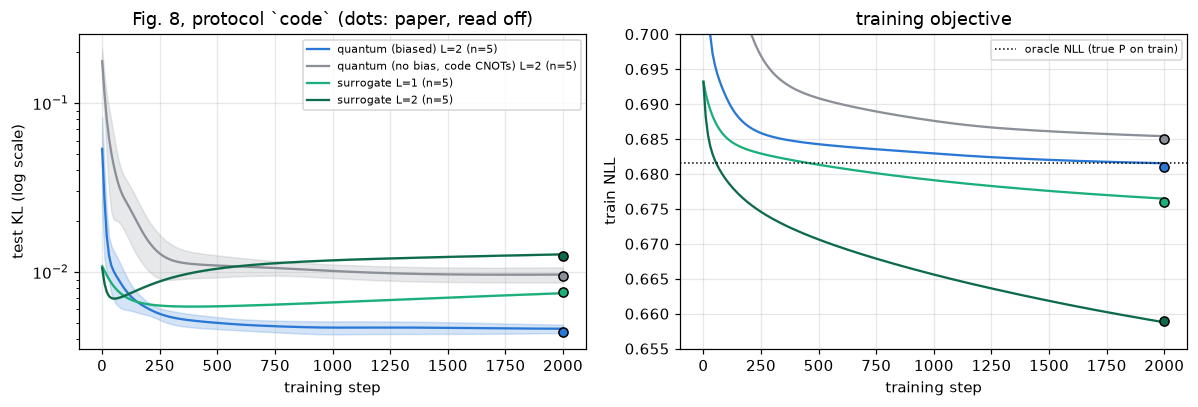

In [12]:
with (RESULTS / "learning_curves.csv").open() as handle:
    CURVES = list(csv.DictReader(handle))

def curve(sweep, system, protocol):
    rows = [r for r in CURVES if r["sweep_id"] == sweep and r["system"] == system and r["protocol"] == protocol]
    if not rows:
        raise KeyError(f"no curve for {sweep} / {system} / {protocol}")
    return {k: np.array([float(r[k]) for r in rows]) for k in ("step", "test_kl_mean", "test_kl_std", "train_nll_mean", "n")}

PAPER = json.loads((RESULTS / "paper_values_read_off.json").read_text())["fig8"]
# Quantum runs under `code`/`fork` live in one sweep and under `paper` in another; surrogates share one sweep.
def fig8_sweep(family, protocol):
    if family == "surrogate":
        return "fig8_surrogates"
    return "fig8_quantum_paper" if protocol == "paper" else "fig8_quantum_code_fork"

FIG8 = [  # (paper curve name, model family, system, colour)
    ("quantum (biased)", "quantum", "quantum (biased) L=2", COLORS["quantum biased"]),
    ("quantum (no bias)", "quantum", "quantum (no bias, code CNOTs) L=2", COLORS["quantum generic"]),
    ("surrogate L=1", "surrogate", "surrogate L=1", COLORS["surrogate"]),
    ("surrogate L=2", "surrogate", "surrogate L=2", "#0e6b4a"),
]

def plot_fig8(protocol, title):
    fig, (ax_kl, ax_nll) = plt.subplots(1, 2, figsize=(11, 3.8))
    for paper_name, family, system, colour in FIG8:
        c = curve(fig8_sweep(family, protocol), system, protocol)
        ax_kl.plot(c["step"], c["test_kl_mean"], color=colour, label=f"{system} (n={int(c['n'][0])})")
        ax_kl.fill_between(c["step"], c["test_kl_mean"] - c["test_kl_std"], c["test_kl_mean"] + c["test_kl_std"], color=colour, alpha=0.2)
        ax_nll.plot(c["step"], c["train_nll_mean"], color=colour)
        if protocol == "code":
            ax_kl.plot(2000, PAPER["final_test_kl"][paper_name], "o", color=colour, mec="k")
            ax_nll.plot(2000, PAPER["final_train_nll"][paper_name], "o", color=colour, mec="k")
    ax_nll.axhline(0.6816, color="k", ls=":", lw=1, label="oracle NLL (true P on train)")
    ax_kl.set(yscale="log", xlabel="training step", ylabel="test KL (log scale)", title=title)
    ax_nll.set(xlabel="training step", ylabel="train NLL", title="training objective", ylim=(0.655, 0.70))
    ax_kl.legend(fontsize=7)
    ax_nll.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

plot_fig8("code", "Fig. 8, protocol `code` (dots: paper, read off)")

In [13]:
def summary(rows, key="final_test_kl"):
    values = np.array([r[key] for r in rows])
    return values.mean(), values.std(ddof=1), len(values)

print(f"{'paper curve':<20} {'metric':<16} {'paper':>8} {'reproduced (mean +- std, n)':>32} {'delta':>7}")
for paper_name, family, system, _ in FIG8:
    rows = stored(fig8_sweep(family, "code"), system, "code")
    for metric, key in (("final test KL", "final_test_kl"), ("final train NLL", "final_train_nll")):
        m, s, n = summary(rows, key)
        paper_value = PAPER["final_test_kl" if key == "final_test_kl" else "final_train_nll"][paper_name]
        print(f"{paper_name:<20} {metric:<16} {paper_value:>8.4g} {m:>18.4e} +- {s:.1e} (n={n}) {100 * (m / paper_value - 1):>+6.1f}%")

paper curve          metric              paper      reproduced (mean +- std, n)   delta
quantum (biased)     final test KL      0.0044         4.6056e-03 +- 2.6e-04 (n=5)   +4.7%
quantum (biased)     final train NLL     0.681         6.8152e-01 +- 3.7e-04 (n=5)   +0.1%
quantum (no bias)    final test KL      0.0095         9.6394e-03 +- 9.9e-04 (n=5)   +1.5%
quantum (no bias)    final train NLL     0.685         6.8539e-01 +- 8.1e-04 (n=5)   +0.1%
surrogate L=1        final test KL      0.0076         7.4811e-03 +- 1.6e-05 (n=5)   -1.6%
surrogate L=1        final train NLL     0.676         6.7646e-01 +- 7.4e-06 (n=5)   +0.1%
surrogate L=2        final test KL      0.0125         1.2707e-02 +- 3.0e-06 (n=5)   +1.7%
surrogate L=2        final train NLL     0.659         6.5877e-01 +- 2.8e-06 (n=5)   -0.0%


**Observation.** Under the author code's evaluation, all four final test KLs agree with the published values within the read-off uncertainty (−1.6% to +4.7%). The final train NLLs agree within 0.001, and the curve shapes match: both surrogates overfit (C9). **Inference.** The implementation, data and training settings are faithful. **Remaining uncertainty.** Paper values were read off log-scale figures by eye.

Two details had to be found by matching:
- The "no bias" curve matches only the author code's entangler, CNOT(1→2) three times (D3). The Fig. 10 entangler is 20-27% better (section 9).
- The train NLL identifies $L=2$ as the plotted depth.

**Claim impact.** The *figure* is reproduced. Whether it supports C7 depends on the evaluation protocol, tested next.

### The same experiment under a consistent evaluation (protocol `paper`)

The paper text scales test inputs by $\pi/2$ like training inputs. With that consistent scaling, nothing changes in training; only the test inputs differ. The seed counts are 20 for the quantum models and 5 for the surrogates; the surrogates' spread across seeds is tiny.

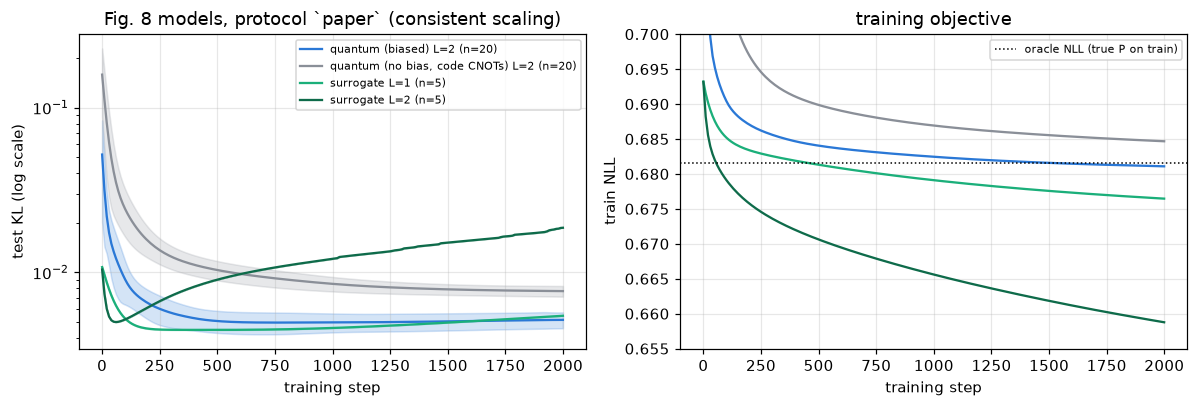

quantum biased L=1           n=20  final test KL 4.080e-03 +- 3.1e-04
quantum biased L=2 (paper)   n=20  final test KL 5.144e-03 +- 5.7e-04
surrogate L=1                n=5   final test KL 5.448e-03 +- 5.7e-06
generic L=1 (Fig. 10)        n=20  final test KL 5.666e-03 +- 5.1e-04
generic L=2 (Fig. 10)        n=20  final test KL 7.023e-03 +- 6.5e-04
generic L=2 (code CNOTs)     n=20  final test KL 7.693e-03 +- 5.7e-04
surrogate L=2                n=5   final test KL 1.865e-02 +- 3.5e-06


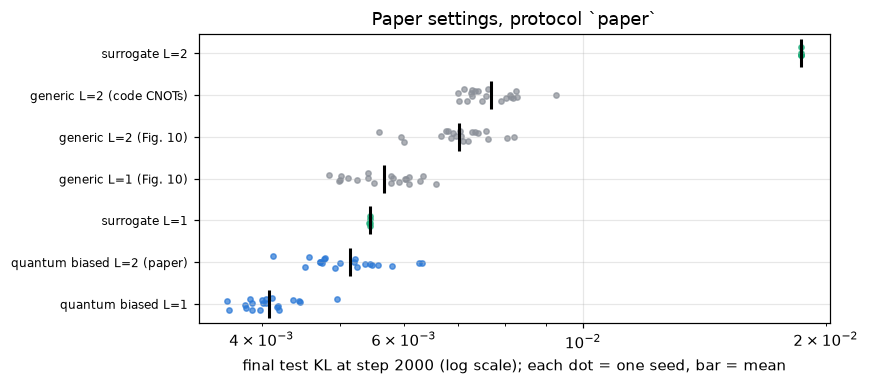


biased L=2 - surrogate L=1: -3.04e-04; Welch p = 0.027, Mann-Whitney p = 0.112


In [14]:
plot_fig8("paper", "Fig. 8 models, protocol `paper` (consistent scaling)")
PAPER_PROTOCOL = [("quantum biased L=1", "fig8_quantum_paper", "quantum (biased) L=1"),
                  ("quantum biased L=2 (paper)", "fig8_quantum_paper", "quantum (biased) L=2"),
                  ("surrogate L=1", "fig8_surrogates", "surrogate L=1"),
                  ("generic L=1 (Fig. 10)", "fig8_quantum_paper", "quantum (no bias, Fig. 10 CNOTs) L=1"),
                  ("generic L=2 (Fig. 10)", "fig8_quantum_paper", "quantum (no bias, Fig. 10 CNOTs) L=2"),
                  ("generic L=2 (code CNOTs)", "fig8_quantum_paper", "quantum (no bias, code CNOTs) L=2"),
                  ("surrogate L=2", "fig8_surrogates", "surrogate L=2")]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (label, sweep, system) in enumerate(PAPER_PROTOCOL):
    values = [r["final_test_kl"] for r in stored(sweep, system)]
    colour = COLORS["surrogate"] if "surrogate" in label else COLORS["quantum generic"] if "generic" in label else COLORS["quantum biased"]
    ax.scatter(values, np.full(len(values), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(values)), s=12, alpha=0.7, color=colour)
    ax.plot(np.mean(values), i, "k|", ms=18, mew=2)
    print(f"{label:<28} n={len(values):<3} final test KL {np.mean(values):.3e} +- {np.std(values, ddof=1):.1e}")
ax.set_yticks(range(len(PAPER_PROTOCOL)), [p[0] for p in PAPER_PROTOCOL], fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("final test KL at step 2000 (log scale); each dot = one seed, bar = mean")
ax.set_title("Paper settings, protocol `paper`")
plt.tight_layout()
plt.show()

a = [r["final_test_kl"] for r in stored("fig8_quantum_paper", "quantum (biased) L=2")]
b = [r["final_test_kl"] for r in stored("fig8_surrogates", "surrogate L=1")]
print(f"\nbiased L=2 - surrogate L=1: {np.mean(a) - np.mean(b):+.2e}; Welch p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.3f}, "
      f"Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}")

**Observation.** Under consistent scaling, the biased $L=2$ model is still lower than the $L=1$ surrogate at the final step. The gap shrinks from about $2.9\times10^{-3}$ (`code`) to $3\times10^{-4}$, which is not resolved by our rule (Welch and Mann-Whitney both $p<0.05$). Biased $L=1$ is the best model in this table.

**Inference.** Most of the published gap comes from the inconsistent test-input scaling, D12. Under `code`, the test features are a copy of the training features shrunk by a factor $2/\pi$: a distribution shift that the surrogates handle worse than the quantum models.

**Remaining uncertainty.** The comparison still gives the quantum model a tuned optimiser and the surrogates fixed tiny-lr SGD, and nothing is selected on held-out data. Section 8 removes these confounders.

**Claim impact.** C7 is **weakened**: the figure is reproduced, but most of its margin is an evaluation artefact.

## 8. Fair baseline comparison

The paper's comparison differs between models in optimiser, learning-rate tuning, parameter count, and in whether any held-out selection exists. To test C7 and C10 fairly, we froze a protocol in `LOG.md` before running anything ("Phase 5 Comparison Plan"; later changes are recorded there as dated amendments). Every model below:

- trains on the same 1500 author samples under protocol `paper`, with 2000 full-batch Adam steps;
- has its learning rate (and, for classical models, L2 strength) chosen by mean final **validation** NLL over tuning seeds 0-2;
- is then trained on **10 fresh seeds (10-19)** and scored by the final-step test KL. A secondary score uses validation-based early stopping.

A difference is called *resolved* only when Welch's t-test and the Mann-Whitney test both give $p<0.05$.

**Fairness, dimension by dimension.** "Matched" is used only where it holds.

| Dimension | Status | Detail |
|---|---|---|
| Information and inputs | matched | All models see the same six features. B2 uses exactly B0's Fourier features; the photonic model uses the same Fourier variables $z(x)$. |
| Parameter count | **partly matched** | Matched at about 91 for the quantum, photonic (90), B3 (97), B4 (93) and B5 (84) models. **Not matched** for B0 (4374) and B2 (8748), which are matched to each other by features. |
| Training data | matched | The same author training set; validation seed 201; test seed 2302. |
| Optimisation steps | matched | 2000 full-batch Adam steps, no early termination. |
| Tuning budget | **not matched** | Every model gets the lr grid {1e-3, 3e-3, 1e-2} × 3 seeds. The classical models also get an L2 grid: 6 values for B0 and B2, 8 for B3-B5. The quantum and photonic models get no L2 grid. |
| Compute and wall time | **not matched (reported)** | Training-loop seconds per run are shown below. They compare implementations, not algorithms. |
| Evaluation protocol | matched | The same test set and metric; final-step KL is primary. Test data never select anything. |

Two of the paper's own baselines need notes:
- The paper's $L=2$ surrogate was not re-tuned (too costly). It appears only as an untuned reference.
- B0, the paper's $L=1$ surrogate under Adam, lost one of its ten final seeds to divergence: its HardTanh output saturates. It is reported with n = 9.

system                                 n          final test KL  early-stopped  params  s/run
B2 bias-encoded Fourier L=1           10    3.606e-03 +- 2.8e-08      3.690e-03    8748    528
photonic group PNR N=2 (MerLin)       10    4.009e-03 +- 9.6e-05      3.965e-03      90    550
quantum biased L=1                    10    4.106e-03 +- 3.7e-04      4.053e-03      55    154
surrogate L=1 (B0), tuned              9    4.415e-03 +- 2.1e-08      4.353e-03    4374    231
B5 quadratic (ceiling)                10    4.521e-03 +- 7.3e-05      4.521e-03      84      9
quantum biased L=2 (paper's model)    10    5.124e-03 +- 4.3e-04      4.733e-03      91    242
quantum generic L=1                   10    5.382e-03 +- 3.1e-04      5.330e-03      54    144
B3 bias-encoded MLP h=7               10    5.762e-03 +- 1.3e-05      5.757e-03      97      9
B4 unbiased MLP h=9                   10    5.779e-03 +- 1.3e-05      5.820e-03      93      8
quantum generic L=2                   10    7.127e-

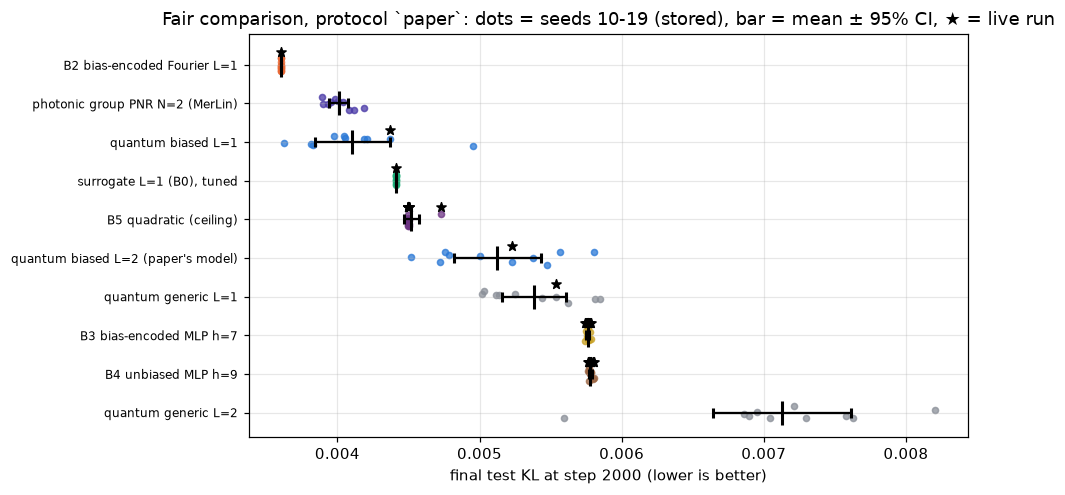

In [15]:
FAIR_SYSTEMS = [  # (display label, sweep system name, colour)
    ("B2 bias-encoded Fourier L=1", "B2 bias-encoded Fourier L=1", COLORS["B2"]),
    ("photonic group PNR N=2 (MerLin)", "photonic MerLin (group readout, PNR) N=2", COLORS["photonic"]),
    ("quantum biased L=1", "quantum (biased) L=1", COLORS["quantum biased"]),
    ("surrogate L=1 (B0), tuned", "surrogate L=1", COLORS["surrogate"]),
    ("B5 quadratic (ceiling)", "B5 quadratic (ceiling)", COLORS["B5"]),
    ("quantum biased L=2 (paper's model)", "quantum (biased) L=2", COLORS["quantum biased"]),
    ("quantum generic L=1", "quantum (no bias, Fig. 10 CNOTs) L=1", COLORS["quantum generic"]),
    ("B3 bias-encoded MLP h=7", "B3 bias-encoded MLP h=7", COLORS["B3"]),
    ("B4 unbiased MLP h=9", "B4 unbiased MLP h=9", COLORS["B4"]),
    ("quantum generic L=2", "quantum (no bias, Fig. 10 CNOTs) L=2", COLORS["quantum generic"]),
]
FINAL = {system: stored("fair_final", system) for _, system, _ in FAIR_SYSTEMS}
live_by_system = {}
for r in LIVE_RESULTS:
    live_by_system.setdefault(SWEEP_NAME[r["label"]], []).append(r["test_kl"])

fig, ax = plt.subplots(figsize=(9, 4.6))
print(f"{'system':<36} {'n':>3} {'final test KL':>22} {'early-stopped':>14} {'params':>7} {'s/run':>6}")
for i, (label, system, colour) in enumerate(FAIR_SYSTEMS):
    rows = FINAL[system]
    values = np.array([r["final_test_kl"] for r in rows])
    jitter = np.random.default_rng(i).uniform(-0.18, 0.18, len(values))
    ax.scatter(values, i + jitter, s=16, color=colour, alpha=0.75)
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / math.sqrt(len(values))
    ax.errorbar(values.mean(), i, xerr=half, fmt="|", color="k", ms=16, mew=2, capsize=3)
    if system in live_by_system:
        ax.scatter(live_by_system[system], np.full(len(live_by_system[system]), i - 0.32), marker="*", s=40, color="k")
    early = np.nanmean([r["early_stop_test_kl"] for r in rows])
    print(f"{label:<36} {len(values):>3} {values.mean():>12.3e} +- {values.std(ddof=1):.1e} {early:>14.3e} "
          f"{rows[0]['n_parameters']:>7} {np.mean([r['train_seconds'] for r in rows]):>6.0f}")
untuned = stored("fig8_surrogates", "surrogate L=2")
print(f"{'surrogate L=2, NOT tuned (Phase 3 SGD)':<36} {len(untuned):>3} {np.mean([r['final_test_kl'] for r in untuned]):>12.3e}"
      f"   (reference only; seeds 0-4; excluded from statistics)")
ax.set_yticks(range(len(FAIR_SYSTEMS)), [s[0] for s in FAIR_SYSTEMS], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("final test KL at step 2000 (lower is better)")
ax.set_title("Fair comparison, protocol `paper`: dots = seeds 10-19 (stored), bar = mean ± 95% CI, ★ = live run")
plt.tight_layout()
plt.show()

In [16]:
def compare(a_system, b_system, sweep="fair_final", key="final_test_kl"):
    a = np.array([r[key] for r in stored(sweep, a_system)])
    b = np.array([r[key] for r in stored(sweep, b_system)])
    welch = stats.ttest_ind(a, b, equal_var=False).pvalue
    mw = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    return a.mean() - b.mean(), welch, mw, bool(welch < 0.05 and mw < 0.05)

STORED_COMPARISONS = {(c["metric"], c["reference"], c["other"]): c
                      for c in json.loads((RESULTS / "fair_comparison.json").read_text())["comparisons"]}
KEY_PAIRS = [
    ("quantum (biased) L=2", "surrogate L=1", "C7/C10: paper's model vs tuned paper surrogate"),
    ("quantum (biased) L=1", "surrogate L=1", "C7: best quantum vs tuned paper surrogate"),
    ("quantum (biased) L=1", "B2 bias-encoded Fourier L=1", "C11: best quantum vs classical with the bias"),
    ("quantum (biased) L=2", "B5 quadratic (ceiling)", "paper's model vs 84-parameter polynomial"),
    ("quantum (biased) L=1", "B5 quadratic (ceiling)", "best quantum vs 84-parameter polynomial"),
    ("quantum (biased) L=1", "quantum (no bias, Fig. 10 CNOTs) L=1", "C8/C11: bias within quantum models"),
]
print(f"{'comparison (reference - other)':<52} {'diff':>10} {'Welch p':>9} {'MW p':>9}  resolved   agrees with stored table")
for a, b, note in KEY_PAIRS:
    for key, metric in (("final_test_kl", "final"), ("early_stop_test_kl", "early-stopped")):
        diff, welch, mw, resolved = compare(a, b, key=key)
        ref = STORED_COMPARISONS[(key, a, b)]
        agrees = abs(ref["diff"] - diff) < 1e-12 and abs(ref["welch_p"] - welch) < 1e-9
        print(f"{note if metric == 'final' else '   (' + metric + ')':<52} {diff:>+10.2e} {welch:>9.1e} {mw:>9.1e}  "
              f"{'yes' if resolved else 'no':<9}  {agrees}")

comparison (reference - other)                             diff   Welch p      MW p  resolved   agrees with stored table
C7/C10: paper's model vs tuned paper surrogate        +7.09e-04   5.4e-04   2.8e-04  yes        True
   (early-stopped)                                    +3.80e-04   7.2e-04   1.7e-03  yes        True
C7: best quantum vs tuned paper surrogate             -3.09e-04   2.6e-02   3.7e-03  yes        True
   (early-stopped)                                    -3.00e-04   6.5e-02   1.6e-02  no         True
C11: best quantum vs classical with the bias          +5.00e-04   2.0e-03   1.8e-04  yes        True
   (early-stopped)                                    +3.63e-04   3.2e-02   1.4e-02  yes        True
paper's model vs 84-parameter polynomial              +6.03e-04   1.5e-03   3.3e-04  yes        True
   (early-stopped)                                    +2.11e-04   2.7e-02   3.8e-02  yes        True
best quantum vs 84-parameter polynomial               -4.16e-04   6.0e-

**Observation.**
1. The paper's model (biased quantum $L=2$) is **beaten** by the equally tuned paper surrogate: $+7.1\times10^{-4}$, resolved. It is also beaten by the 84-parameter polynomial B5.
2. Biased $L=1$ beats the tuned surrogate at the final step ($-3.1\times10^{-4}$, resolved), but not with validation early stopping.
3. The classical model with the zero-sum bias hard-coded (**B2**) is the best system overall. It beats every quantum and photonic model (all resolved), with almost no seed variance.
4. At about 91 parameters, biased quantum $L=1$ and the photonic model beat the classical MLPs B3 and B4 and the polynomial B5. The paper's $L=2$ model beats only B3 and B4.

The live runs (★) fall on the stored distributions.

**Inference.**
- Equal tuning removes the advantage of the paper's $L=2$ setting.
- The best quantum model keeps a small, protocol-dependent edge over the paper surrogate.
- The *bias itself* is easy to encode classically, and doing so is what wins.

**Remaining uncertainty.**
- The tuning budgets are not matched: the quantum models received no L2 grid.
- B2 has about 96× more parameters than the quantum models, so compactness remains a real quantum and photonic advantage in this study.

**Claim impact.**
- C7 (biased model lowest): **contradicted** under fair tuning.
- C10 (regularisation cannot close the gap): **contradicted**. The validation-selected L2 = 1 surrogate beats the paper's $L=2$ model.
- C11 ("cannot be easily encoded"): **contradicted** in its classical-encodability part.

## 9. Controls and ablations

The paper explains the gap by the zero-sum bias. Credible alternative explanations are:
- the evaluation protocol;
- a weak generic baseline;
- implementation details of the ansatz;
- contextuality rather than the bias.

Each control below changes one factor.

### 9a. Bias on vs off, within the same model family

Fourier features (B2 vs B0)                  with - without bias = -8.09e-04  (Welch p 1.0e-71, MW p 2.8e-04, resolved: True)
MLP ~95 params (B3 vs B4)                    with - without bias = -1.76e-05  (Welch p 7.7e-03, MW p 1.1e-02, resolved: True)
quantum L=1 (biased vs generic)              with - without bias = -1.28e-03  (Welch p 1.6e-07, MW p 1.8e-04, resolved: True)
quantum L=2 (biased vs generic)              with - without bias = -2.00e-03  (Welch p 9.6e-07, MW p 2.5e-04, resolved: True)
photonic N=2 threshold (group vs unbiased)   with - without bias = -1.45e-03  (Welch p 5.8e-04, MW p 3.6e-03, resolved: True)


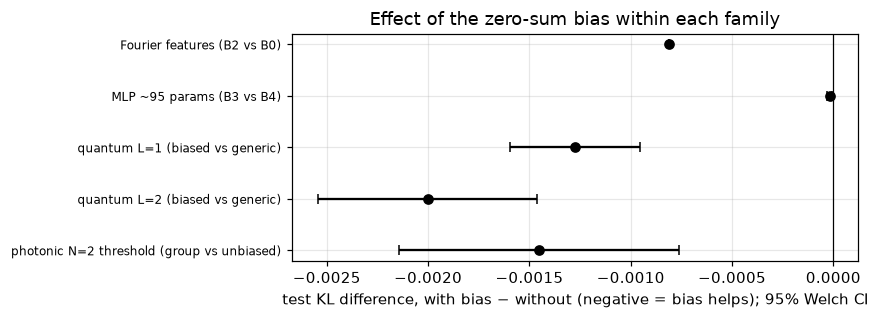

In [17]:
PAIRS_BIAS = [  # (family, with-bias system, without-bias system, sweep)
    ("Fourier features (B2 vs B0)", "B2 bias-encoded Fourier L=1", "surrogate L=1", "fair_final"),
    ("MLP ~95 params (B3 vs B4)", "B3 bias-encoded MLP h=7", "B4 unbiased MLP h=9", "fair_final"),
    ("quantum L=1 (biased vs generic)", "quantum (biased) L=1", "quantum (no bias, Fig. 10 CNOTs) L=1", "fair_final"),
    ("quantum L=2 (biased vs generic)", "quantum (biased) L=2", "quantum (no bias, Fig. 10 CNOTs) L=2", "fair_final"),
    ("photonic N=2 threshold (group vs unbiased)", "photonic MerLin (group readout, threshold) N=2",
     "photonic MerLin (unbiased readout, threshold) N=2", "fig8_photonic_merlin"),
]
fig, ax = plt.subplots(figsize=(8, 3))
for i, (family, biased, unbiased, sweep) in enumerate(PAIRS_BIAS):
    a = np.array([r["final_test_kl"] for r in stored(sweep, biased)])
    b = np.array([r["final_test_kl"] for r in stored(sweep, unbiased)])
    diff, welch, mw, resolved = compare(biased, unbiased, sweep=sweep)
    va, vb = a.var(ddof=1) / a.size, b.var(ddof=1) / b.size
    dof = (va + vb) ** 2 / (va ** 2 / (a.size - 1) + vb ** 2 / (b.size - 1))
    half = stats.t.ppf(0.975, dof) * math.sqrt(va + vb)
    ax.errorbar(diff, i, xerr=half, fmt="o", color="k" if resolved else "#aaa", capsize=3)
    print(f"{family:<44} with - without bias = {diff:+.2e}  (Welch p {welch:.1e}, MW p {mw:.1e}, resolved: {resolved})")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(PAIRS_BIAS)), [p[0] for p in PAIRS_BIAS], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("test KL difference, with bias − without (negative = bias helps); 95% Welch CI")
ax.set_title("Effect of the zero-sum bias within each family")
plt.tight_layout()
plt.show()

**Observation.** Adding the bias lowers the test KL in every family. The effect is large for the Fourier, quantum and photonic models, and tiny ($-1.8\times10^{-5}$) for the MLPs.

**Inference.** The bias is a genuine, model-independent inductive bias. Its benefit depends on the function class it is combined with.

**Claim impact.** This **supports** the "gain comes from the bias" part of C11. Its strongest instance, though, is classical (B2 vs B0).

### 9b. Evaluation protocol (D12), generic entangler (D3) and ZZ repetitions (D4)

These are the paper-setting runs: 5 seeds per protocol for the code and fork evaluations, and 20 for paper.

In [18]:
print("Gap 'biased L=2 - surrogate L=1' (paper settings) under each evaluation protocol:")
for protocol in ("code", "paper", "fork"):
    a = np.array([r["final_test_kl"] for r in stored(fig8_sweep("quantum", protocol), "quantum (biased) L=2", protocol)])
    b = np.array([r["final_test_kl"] for r in stored("fig8_surrogates", "surrogate L=1", protocol)])
    print(f"  {protocol:<6} {a.mean() - b.mean():+.2e}   (biased {a.mean():.3e}, n={a.size}; surrogate {b.mean():.3e}, n={b.size}; "
          f"Welch p {stats.ttest_ind(a, b, equal_var=False).pvalue:.1e})")

print("\nGeneric model, protocol `code`, L=2: published entangler vs Fig. 10 entangler")
for system in ("quantum (no bias, code CNOTs) L=2", "quantum (no bias, Fig. 10 CNOTs) L=2"):
    m, s, n = summary(stored("fig8_quantum_code_fork", system, "code"))
    print(f"  {system:<40} {m:.3e} +- {s:.1e} (n={n})   paper: {PAPER['final_test_kl']['quantum (no bias)']}")

print("\nBiased model: ZZ applied once per block (Fig. 7) vs three times (author code), seeds 0-4")
for protocol in ("code", "paper"):
    for layers in (1, 2):
        system = f"quantum (biased) L={layers}"
        zz3 = summary(stored("fig8_biased_zz3_control", system, protocol))
        zz1 = summary([r for r in stored(fig8_sweep("quantum", protocol), system, protocol) if r["seed"] < 5])
        print(f"  {protocol:<6} L={layers}: zz=3 {zz3[0]:.3e} +- {zz3[1]:.1e}   zz=1 {zz1[0]:.3e} +- {zz1[1]:.1e}")

Gap 'biased L=2 - surrogate L=1' (paper settings) under each evaluation protocol:
  code   -2.88e-03   (biased 4.606e-03, n=5; surrogate 7.481e-03, n=5; Welch p 1.4e-05)
  paper  -3.04e-04   (biased 5.144e-03, n=20; surrogate 5.448e-03, n=5; Welch p 2.7e-02)
  fork   -6.72e-04   (biased 3.604e-03, n=5; surrogate 4.276e-03, n=5; Welch p 7.0e-04)

Generic model, protocol `code`, L=2: published entangler vs Fig. 10 entangler
  quantum (no bias, code CNOTs) L=2        9.639e-03 +- 9.9e-04 (n=5)   paper: 0.0095
  quantum (no bias, Fig. 10 CNOTs) L=2     7.645e-03 +- 7.8e-04 (n=5)   paper: 0.0095

Biased model: ZZ applied once per block (Fig. 7) vs three times (author code), seeds 0-4
  code   L=1: zz=3 4.726e-03 +- 1.6e-04   zz=1 4.675e-03 +- 1.3e-04
  code   L=2: zz=3 4.660e-03 +- 1.3e-04   zz=1 4.606e-03 +- 2.6e-04
  paper  L=1: zz=3 4.063e-03 +- 3.6e-04   zz=1 4.040e-03 +- 3.1e-04
  paper  L=2: zz=3 5.144e-03 +- 3.5e-04   zz=1 4.828e-03 +- 5.3e-04


**Observation.**
- The biased-vs-surrogate gap is about ten times larger under the author code's evaluation (`code`) than under consistent scaling (`paper`). Under `fork` it is in between.
- The published "no bias" curve (9.5e-3) matches the author code's repeated-CNOT entangler. The Fig. 10 entangler gives a stronger baseline (7.6e-3).
- Repeating the ZZ gates changes nothing beyond the seed noise.

**Inference.** Two artefacts of the author code inflate the published Fig. 8 gap: the test scaling and the weaker entangler. The ansatz detail is immaterial.

**Claim impact.** C7 and C8 are **weakened**: their published margins depend on author-code choices.

### 9c. Is it contextuality? Witness of the trained models (extension X1)

Theorem 4.1 gives a test. A trained biased model can only be contextual if its set of behaviours contains $V_\eta$ for some $\eta>2/3$. For each of the six hexagon directions, a linear program finds the largest $t$ such that $c+t(v_i-c)$ lies in the convex hull of the model's behaviours; the witness is $\eta=\min_i t_i$.

The model's behaviours are evaluated on:
- the 10000 test inputs;
- the 27 deterministic strategies;
- 3000 "corner" strategies.

A finite input set gives a lower bound on $\eta$. Here we compute it live for the two models trained in section 6, then show the stored result for every final run.

In [19]:
from run_extensions import corner_strategies, witness_eta

corners = corner_strategies(3000, 0.1, 7)
corner_features = torch.as_tensor(data_lib.compress_strategies(corners, math.pi / 2), dtype=DTYPE)
truth_eta = witness_eta(rps_game.win_probabilities(corners))
print(f"ground truth on the corner inputs: eta = {truth_eta:.3f}  (threshold for contextuality: 2/3)")
for label in ("quantum biased L=1", "quantum biased L=2", "B2 bias-encoded Fourier L=1", "B3 bias-encoded MLP h=7"):
    model = LIVE_MODELS[(label, 10)]
    with torch.no_grad():
        behaviours = (1 + torch.cat([model(test_split.features), model(corner_features)])).numpy() / 2
    print(f"live  {label:<30} seed 10: eta = {witness_eta(behaviours):.3f}")

x1 = json.loads((RESULTS / "extension_x1_witness.json").read_text())["models"]
print("\nstored, all final runs (10 seeds each):")
for name, info in sorted(x1.items()):
    if "eta_mean" in info:
        print(f"  {name:<44} eta mean {info['eta_mean']:.3f} (min {info['eta_min']:.3f}, max {info['eta_max']:.3f}), contextual runs {info['contextual_runs']}/{info['n']}")

ground truth on the corner inputs: eta = 1.000  (threshold for contextuality: 2/3)


live  quantum biased L=1             seed 10: eta = 0.373


live  quantum biased L=2             seed 10: eta = 0.503


live  B2 bias-encoded Fourier L=1    seed 10: eta = 0.252


live  B3 bias-encoded MLP h=7        seed 10: eta = 0.182

stored, all final runs (10 seeds each):
  B2 bias-encoded Fourier L=1                  eta mean 0.252 (min 0.252, max 0.252), contextual runs 0/10
  B3 bias-encoded MLP h=7                      eta mean 0.181 (min 0.178, max 0.183), contextual runs 0/10
  photonic MerLin (group readout, PNR) N=2     eta mean 0.335 (min 0.300, max 0.389), contextual runs 0/10
  quantum (biased) L=1                         eta mean 0.386 (min 0.339, max 0.480), contextual runs 0/10
  quantum (biased) L=2                         eta mean 0.518 (min 0.372, max 0.639), contextual runs 0/10


**Observation.**
- No trained model is contextual: every witness is well below 2/3. The highest is the paper's $L=2$ model, at 0.52 on average.
- The ground truth reaches $\eta=1$ on the same inputs. The best-generalising model, B2, has one of the *smallest* witnesses.
- Section 11 adds the photonic test: a readout that is noncontextual *by construction* performs as well as one that can be contextual.

**Inference.** On this task the models' advantage cannot come from contextuality. Fitting the data does not require behaviours outside $V_{2/3}$, consistent with the 0.1% of test behaviours that lie there (section 2).

**Remaining uncertainty.** The witness is a lower bound on a finite input set. A model could reach further on inputs we did not try. Corner strategies were included to probe exactly that.

**Claim impact.** A contextuality-based reading of C11 is **not supported**. This is an extension; the paper does not claim the trained models are contextual.

### 9d. Where in the input space does each model win? (extension X2)

The test KL of the same final runs is split by the true behaviour's distance $d$ from the centre.

test points per stratum: {'[0.0, 0.1)': 7032, '[0.1, 0.2)': 2588, '[0.2, 0.5]': 380}


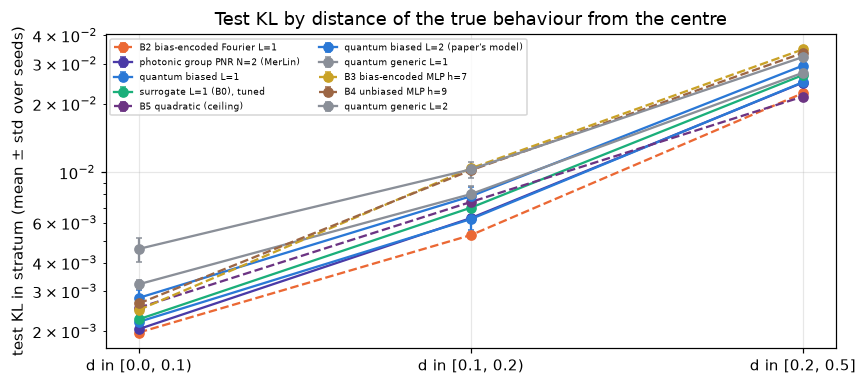

quantum (biased) L=2                       - surrogate L=1                          [0.0, 0.1)  +5.47e-04  resolved: True
quantum (biased) L=2                       - surrogate L=1                          [0.1, 0.2)  +8.58e-04  resolved: True
quantum (biased) L=2                       - surrogate L=1                          [0.2, 0.5]  +2.69e-03  resolved: True
quantum (biased) L=1                       - surrogate L=1                          [0.0, 0.1)  -5.84e-05  resolved: False
quantum (biased) L=1                       - surrogate L=1                          [0.1, 0.2)  -7.62e-04  resolved: True
quantum (biased) L=1                       - surrogate L=1                          [0.2, 0.5]  -1.87e-03  resolved: False
quantum (biased) L=1                       - B2 bias-encoded Fourier L=1            [0.0, 0.1)  +2.25e-04  resolved: True
quantum (biased) L=1                       - B2 bias-encoded Fourier L=1            [0.1, 0.2)  +9.33e-04  resolved: True
quantum (biased) L=1  

In [20]:
x2 = json.loads((RESULTS / "extension_x2_stratified.json").read_text())
print("test points per stratum:", dict(zip(x2["strata"], x2["test_points_per_stratum"])))
fig, ax = plt.subplots(figsize=(8, 3.6))
for label, system, colour in FAIR_SYSTEMS:
    info = x2["models"][system]
    ax.errorbar(range(3), info["mean"], yerr=info["std"], marker="o", color=colour, capsize=2,
                label=label, ls="-" if "B" not in label[:2] else "--")
ax.set_xticks(range(3), [f"d in {s}" for s in x2["strata"]])
ax.set_yscale("log")
ax.set_ylabel("test KL in stratum (mean ± std over seeds)")
ax.legend(fontsize=6, ncol=2)
ax.set_title("Test KL by distance of the true behaviour from the centre")
plt.tight_layout()
plt.show()
for c in x2["comparisons"]:
    print(f"{c['reference']:<42} - {c['other']:<38} {c['stratum']:<11} {c['diff']:+.2e}  resolved: {c['resolved']}")

**Observation.**
- Errors grow with distance from the centre for every model, and the benefit of the bias grows with it.
- B2 is better than every quantum and photonic model in every stratum, all resolved.
- In the outermost stratum, B5 and B2 are the two lowest.

**Claim impact.** No region of the input space shows an advantage for the quantum models over the classical bias-encoded model. This is advantage-type evidence, because the baselines ran under identical conditions.

## 10. Robustness and uncertainty

**Data robustness.** Every fair-comparison model was retrained (init seed 10) on three *regenerated* training sets (data seeds 101-103), with the same validation and test sets. Lines connect the same model across data sets.

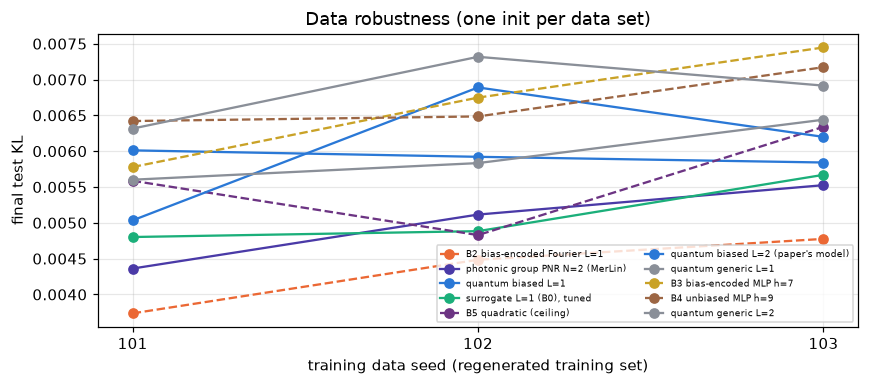

B2 bias-encoded Fourier L=1                vs quantum (biased) L=1   mean diff -1.59e-03, first lower on 3/3 data sets, paired t p = 0.047
B2 bias-encoded Fourier L=1                vs quantum (biased) L=2   mean diff -1.71e-03, first lower on 3/3 data sets, paired t p = 0.039
surrogate L=1                              vs quantum (biased) L=1   mean diff -8.06e-04, first lower on 3/3 data sets, paired t p = 0.13
surrogate L=1                              vs quantum (biased) L=2   mean diff -9.23e-04, first lower on 3/3 data sets, paired t p = 0.23
photonic MerLin (group readout, PNR) N=2   vs quantum (biased) L=1   mean diff -9.24e-04, first lower on 3/3 data sets, paired t p = 0.14


In [21]:
fig, ax = plt.subplots(figsize=(8, 3.6))
robust = {}
for label, system, colour in FAIR_SYSTEMS:
    rows = stored("fair_robustness", system, train_source="generated")
    values = [r["final_test_kl"] for r in rows]
    robust[system] = dict(zip([r["train_seed"] for r in rows], values))
    ax.plot([r["train_seed"] for r in rows], values, marker="o", color=colour, label=label,
            ls="-" if "B" not in label[:2] else "--")
ax.set_xlabel("training data seed (regenerated training set)")
ax.set_ylabel("final test KL")
ax.legend(fontsize=6, ncol=2)
ax.set_title("Data robustness (one init per data set)")
plt.tight_layout()
plt.show()

def paired(a, b):
    seeds = sorted(robust[a])
    diff = np.array([robust[a][s] - robust[b][s] for s in seeds])
    return diff.mean(), int((diff < 0).sum()), stats.ttest_rel([robust[a][s] for s in seeds], [robust[b][s] for s in seeds]).pvalue

for a, b in (("B2 bias-encoded Fourier L=1", "quantum (biased) L=1"), ("B2 bias-encoded Fourier L=1", "quantum (biased) L=2"),
             ("surrogate L=1", "quantum (biased) L=1"), ("surrogate L=1", "quantum (biased) L=2"),
             ("photonic MerLin (group readout, PNR) N=2", "quantum (biased) L=1")):
    mean, lower, p = paired(a, b)
    print(f"{a:<42} vs {b:<22} mean diff {mean:+.2e}, first lower on {lower}/3 data sets, paired t p = {p:.2g}")

**Observation.**
- Across regenerated training sets, B2 is lower than both biased quantum models on 3/3 data sets (paired $p\approx0.04$).
- The tuned surrogate is lower than both biased models on 3/3 data sets, but this is not significant with three data sets.

**Uncertainty, summarised.**
- *Seeds*: 10 per model in the fair comparison. The individual values are shown in section 8, with 95% CIs.
- *Data*: 3 regenerated sets, one init each, so this check has low power.
- *Checkpoint*: the final step is primary. With validation early stopping, the biased $L=1$ vs tuned surrogate difference is no longer resolved.
- *Paper values*: read off figures by eye, about ±5%.

**Claim impact.** Robustness does not rescue C7. The only quantum win in section 8 (biased $L=1$ vs the tuned surrogate on the author data) **reverses** on all three regenerated data sets.

## 11. Photonic assessment (MerLin adaptation)

This section is an **adaptation**, not part of the paper.

**Question.** Can a linear-optical model encode the zero-sum bias, and does it behave like the biased qubit model?

**Mapping.** A passive linear-optical circuit conserves photon number: every detected outcome $n=(n_1,\dots,n_6)$ has $\sum_m n_m=N$. A readout that maps each outcome to a point of the zero-sum hexagon therefore makes the model's prediction a convex combination of zero-sum points. The bias then holds **exactly**, for every input and parameter value. This is the photonic counterpart of "generators commute with $Z_1+Z_2+Z_3$".

**Circuit** (`lib/photonic_merlin.py`):
- 6 modes and $N=2$ photons;
- three trainable MZI meshes, 90 parameters, the same count as the biased $L=2$ qubit model;
- the same Fourier variables $z(x)$ as phase encodings, uploaded twice.

**Readouts:**
- **vertex**: outcome fractions mapped onto the six hexagon vertices. This readout can reach contextual behaviours.
- **group**: each player owns two modes, and $P_k(+1)=\tfrac14+\tfrac34\,(\text{photons in }k\text{'s group})/N$. Each outcome maps injectively to a mixture of noncontextual responses, so the model is **provably noncontextual**.
- **unbiased**: a free trainable readout (+18 parameters). It is the control.

**Detection:**
- UNBUNCHED: threshold detectors. MerLin keeps only collision-free outcomes and renormalises, i.e. it postselects.
- FOCK: photon-number-resolving detectors, no postselection.

In [22]:
from contextuality_inductive_bias.lib.photonic_merlin import PhotonicZeroSumModel

x = test_split.features[:1000]
for readout in ("vertex", "group", "unbiased"):
    for space in ("unbunched", "fock"):
        torch.manual_seed(0)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = PhotonicZeroSumModel(readout, 2, CFG["model"]["input_states"]["2"], 2, DTYPE, computation_space=space)
        with torch.no_grad():
            photons = model.occupations.sum(dim=1)
            keep = model.postselection_success(x)
            violation = metrics_lib.zero_sum_violation(model(x))
        print(f"{readout:<9} {space:<10} outcomes {len(photons):>3} (all with N={int(photons.min())}), "
              f"max |sum_k E| = {violation:.1e}, keep rate at init {float(keep.mean()):.2f} (min {float(keep.min()):.2f})")

vertex    unbunched  outcomes  15 (all with N=2), max |sum_k E| = 1.1e-15, keep rate at init 0.93 (min 0.75)
vertex    fock       outcomes  21 (all with N=2), max |sum_k E| = 9.2e-15, keep rate at init 1.00 (min 1.00)
group     unbunched  outcomes  15 (all with N=2), max |sum_k E| = 8.9e-16, keep rate at init 0.93 (min 0.75)


group     fock       outcomes  21 (all with N=2), max |sum_k E| = 8.7e-15, keep rate at init 1.00 (min 1.00)
unbiased  unbunched  outcomes  15 (all with N=2), max |sum_k E| = 6.6e-02, keep rate at init 0.93 (min 0.75)
unbiased  fock       outcomes  21 (all with N=2), max |sum_k E| = 6.7e-02, keep rate at init 1.00 (min 1.00)


**Observation.**
- Every outcome holds exactly $N=2$ photons.
- The vertex and group readouts satisfy the constraint to machine precision under both detectors; the unbiased readout does not.
- With threshold detection, an untrained circuit (seed 0) keeps about 93% of ideal shots on average, and 75% for the worst input.

**Live check.** Next we train the fair-comparison photonic model live: group readout, PNR, lr 3e-3 chosen on validation, seed 10. We compare it with the stored run.

In [23]:
label = "photonic group PNR N=2"
extra = {"readout": "group", "n_photons": 2, "computation_space": "fock"}
live_photonic = run_live(label, "photonic_merlin", extra, 10)
LIVE_RESULTS.append(live_photonic)
stored_photonic = [r for r in stored("fair_final", SWEEP_NAME[label]) if r["seed"] == 10][0]
print(f"live  final test KL {live_photonic['test_kl']:.6e} in {live_photonic['seconds']:.0f} s")
print(f"stored final test KL {stored_photonic['final_test_kl']:.6e} (same seed, fair_final)")

live  final test KL 3.902267e-03 in 79 s
stored final test KL 3.902267e-03 (same seed, fair_final)


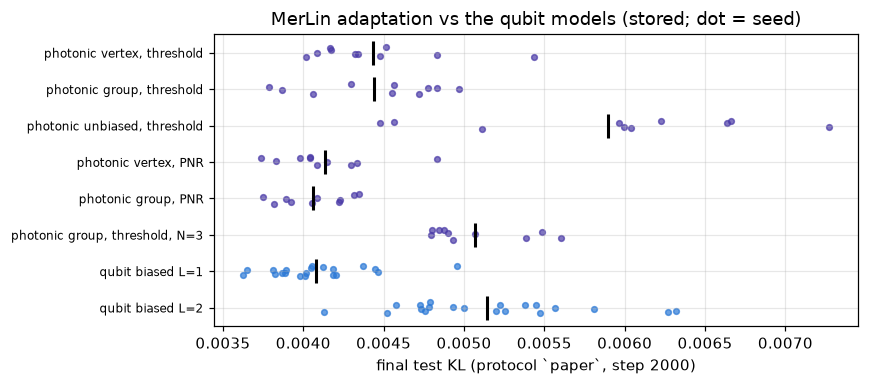

noncontextual group - contextual-capable vertex (threshold): +5.80e-06, Welch p 0.98, MW p 0.79
noncontextual group - contextual-capable vertex (PNR): -6.88e-05, Welch p 0.57, MW p 0.85


### MerLin adaptation: hardware-aware results (protocol paper, final step 2000)

| Readout | Computation space | Detector | Photons | Modes | Input state | Encoding | Measurement | Postselection | Mean keep rate (test) | Worst sample keep rate | Simulator | Shots | Wall-clock per run (s, mean) | Seeds | Final test KL (mean +- std) | max \|sum_k E\| |
|---|---|---|---:|---:|---|---|---|---|---:|---:|---|---|---:|---|---|---:|
| group | FOCK (photon-number-resolving, no postselection) | photon-number-resolving | 2 | 6 | [1, 0, 0, 1, 0, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | none | 1.000 | 1.000 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 492 | 0-9 (n=10) | 4.064e-03 +- 2.1e-04 | 1.0e-14 |
| group | UNBUNCHED (collision-free postselection, renormalised) | threshold | 2 | 6 | [1, 0, 0, 1, 0, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | collision-free outcomes (exactly one photon per clicked mode) | 0.573 | 0.096 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 526 | 0-9 (n=10) | 4.442e-03 +- 4.2e-04 | 1.4e-15 |
| group | UNBUNCHED (collision-free postselection, renormalised) | threshold | 3 | 6 | [1, 0, 1, 0, 1, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | collision-free outcomes (exactly one photon per clicked mode) | 0.217 | 0.008 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 753 | 0-9 (n=10) | 5.069e-03 +- 3.1e-04 | 1.7e-15 |
| unbiased | UNBUNCHED (collision-free postselection, renormalised) | threshold | 2 | 6 | [1, 0, 0, 1, 0, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | collision-free outcomes (exactly one photon per clicked mode) | 0.442 | 0.018 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 524 | 0-9 (n=10) | 5.895e-03 +- 9.2e-04 | 5.1e-01 |
| unbiased | UNBUNCHED (collision-free postselection, renormalised) | threshold | 3 | 6 | [1, 0, 1, 0, 1, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | collision-free outcomes (exactly one photon per clicked mode) | 0.073 | 0.001 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 634 | 0-9 (n=10) | 7.064e-03 +- 7.5e-04 | 5.1e-01 |
| vertex | FOCK (photon-number-resolving, no postselection) | photon-number-resolving | 2 | 6 | [1, 0, 0, 1, 0, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | none | 1.000 | 1.000 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 574 | 0-9 (n=10) | 4.132e-03 +- 3.1e-04 | 1.0e-14 |
| vertex | UNBUNCHED (collision-free postselection, renormalised) | threshold | 2 | 6 | [1, 0, 0, 1, 0, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | collision-free outcomes (exactly one photon per clicked mode) | 0.627 | 0.116 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 546 | 0-9 (n=10) | 4.436e-03 +- 4.3e-04 | 1.4e-15 |
| vertex | UNBUNCHED (collision-free postselection, renormalised) | threshold | 3 | 6 | [1, 0, 1, 0, 1, 0] | z(x) phases, L=2 re-uploading | probs + linear readout | collision-free outcomes (exactly one photon per clicked mode) | 0.172 | 0.012 | MerLin 0.4.1 exact CPU simulation (no sampling, shots = 0) | n/a (exact) | 547 | 0-9 (n=10) | 5.652e-03 +- 9.0e-04 | 1.9e-15 |


In [24]:
from IPython.display import Markdown, display

PHOTONIC = [  # Phase 4 sweeps, protocol `paper`, seeds 0-9, plus the qubit models at the same settings (seeds 0-19)
    ("photonic vertex, threshold", "fig8_photonic_merlin", "photonic MerLin (vertex readout, threshold) N=2"),
    ("photonic group, threshold", "fig8_photonic_merlin", "photonic MerLin (group readout, threshold) N=2"),
    ("photonic unbiased, threshold", "fig8_photonic_merlin", "photonic MerLin (unbiased readout, threshold) N=2"),
    ("photonic vertex, PNR", "fig8_photonic_merlin_fock", "photonic MerLin (vertex readout, PNR) N=2"),
    ("photonic group, PNR", "fig8_photonic_merlin_fock", "photonic MerLin (group readout, PNR) N=2"),
    ("photonic group, threshold, N=3", "fig8_photonic_merlin", "photonic MerLin (group readout, threshold) N=3"),
    ("qubit biased L=1", "fig8_quantum_paper", "quantum (biased) L=1"),
    ("qubit biased L=2", "fig8_quantum_paper", "quantum (biased) L=2"),
]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (label, sweep, system) in enumerate(PHOTONIC):
    values = np.array([r["final_test_kl"] for r in stored(sweep, system)])
    colour = COLORS["photonic"] if label.startswith("photonic") else COLORS["quantum biased"]
    ax.scatter(values, i + np.random.default_rng(i).uniform(-0.15, 0.15, values.size), s=14, color=colour, alpha=0.7)
    ax.plot(values.mean(), i, "k|", ms=16, mew=2)
ax.set_yticks(range(len(PHOTONIC)), [p[0] for p in PHOTONIC], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("final test KL (protocol `paper`, step 2000)")
ax.set_title("MerLin adaptation vs the qubit models (stored; dot = seed)")
plt.tight_layout()
plt.show()
for a, b in (("photonic MerLin (group readout, threshold) N=2", "photonic MerLin (vertex readout, threshold) N=2"),
             ("photonic MerLin (group readout, PNR) N=2", "photonic MerLin (vertex readout, PNR) N=2")):
    sweep = "fig8_photonic_merlin_fock" if "PNR" in a else "fig8_photonic_merlin"
    diff, welch, mw, resolved = compare(a, b, sweep=sweep)
    print(f"noncontextual group - contextual-capable vertex ({'PNR' if 'PNR' in a else 'threshold'}): {diff:+.2e}, Welch p {welch:.2f}, MW p {mw:.2f}")
display(Markdown((RESULTS / "merlin_hardware_aware.md").read_text()))

**Observation.**
1. The biased photonic readouts match the best qubit model, and the unbiased readout is clearly worse. This is the same bias effect as in section 9a.
2. The **noncontextual** group readout performs exactly like the contextual-capable vertex readout ($p\ge0.5$ under both detectors).
3. With threshold detection, training drifts towards bunched states. Trained biased readouts keep only 57-63% of shots at $N=2$, and 17-22% at $N=3$. PNR detection keeps every shot and is slightly better.
4. In the fair comparison (section 8), the photonic group PNR model ties biased qubit $L=1$ and loses to the classical B2.

**Inference.**
- Photonics is a natural, exact host for this kind of conservation-law bias.
- Contextuality plays no role: a model that cannot be contextual does just as well.

**Remaining uncertainty.**
- Every result is an exact simulation (MerLin 0.4.1, no shots, no loss).
- Photon loss would break exact conservation unless one postselects on $N$ detected photons.
- More photons at fixed modes ($N=3$) did not help.

**Verdict for the adaptation.** `MERLIN_IMPLEMENTATION`: the scientific role (an exact zero-sum bias at about 90 parameters) is preserved and executed. There is no photonic advantage over a classical bias-encoded model.

## 12. Claim-level conclusion

### Five separate questions

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | Yes. Every model trains and evaluates, and the live runs reproduce the stored runs bit for bit. | §6 |
| Does the method solve the task? | Yes. Every model learns the payoff behaviours far better than the constant model, with test KL about $4\text{-}7\times10^{-3}$. | §7, §8 |
| Does the paper's metric reproduce? | Yes, under the author code's evaluation: within −1.6% to +4.7% of the published Fig. 8 values. The theory is exact. | §4, §7 |
| Does the paper's explanation survive controls? | Partly. The bias helps in every model family. Contextuality is not needed, and no trained model is contextual. | §9a, §9c, §11 |
| Does the method beat a fair baseline? | **No.** Under equal tuning, the paper's $L=2$ model loses to the tuned surrogate, and a classical model with the bias hard-coded beats every quantum model. | §8, §10 |

### Final verdict

1. **What reproduced.**
   - Lemma 4.1 and Theorem 4.1: bound 5/2, threshold 2/3, both exact (§4).
   - The bias-encoding constructions (§4).
   - The Fig. 8 numbers and curve shapes under the author code's evaluation (§7).
   - Surrogate overfitting, C9 (§7).
   - The direction "biased beats generic quantum", C8's quantum half (§8, §9a).
2. **What did not reproduce.**
   - **C7.** The biased quantum model does not have the lowest test KL once all models are tuned on validation data (§8). Most of the published margin comes from the author code's test scaling and its weaker generic entangler (§7, §9b).
   - **C10.** A validation-selected L2 strength *does* bring the surrogate to the paper model's level, and beyond it (§8).
   - **C11, encodability.** The claim that the bias cannot easily be encoded classically fails: a classical softmax over the six hexagon vertices encodes it exactly and generalises best (§8, §9a, §10).
3. **What remains unresolved.**
   - Whether biased $L=1$ truly beats the tuned surrogate. It is resolved at the final step on the author data, but not with early stopping, and it reverses on 3/3 regenerated data sets (§8, §10).
   - Whether the quantum and photonic models would gain from an L2 grid, which they did not receive (§8).
   - Whether the conclusions change for more tasks ($m>3$), where classical bias encodings may grow quickly.
4. **What was not attempted.**
   - Re-tuning the $L=2$ surrogate.
   - Hardware or QPU runs.
   - Photon loss and noise models.
   - Other datasets.
5. **Reproduction verdict: partially reproduced.** The theory and the published numbers reproduce. The paper's empirical conclusion, that the biased quantum model beats classical alternatives, does not survive a fair comparison. *The zero-sum bias is real and useful, but on this task it is neither quantum-specific nor contextual.*
6. **Photonic verdict.** `MERLIN_IMPLEMENTATION` (§11):
   - photon-number conservation encodes the bias exactly;
   - the adaptation matches the best qubit model at 90 parameters;
   - a provably noncontextual readout performs equally well;
   - there is no advantage over the classical bias-encoded model.

At about 91 parameters, the quantum and photonic models are more compact than the best classical model (8748 parameters). This is the one advantage that survives, and it is not the one the paper claims.

## Limitations

**Reductions and deviations, and their likely impact:**

| Item | What was done | Likely impact |
|---|---|---|
| Live budget | Expensive models run live on one seed (10). B3-B5 run live on all 10 seeds. Everything else is loaded from stored full runs, and §6 checks the stored runs against live ones. | None on the conclusions: they rest on the stored 10-seed runs, which the live runs match exactly. |
| Framework | PyTorch reimplementation, not the authors' JAX/PennyLane code. The simulator and optimisers are tested against PennyLane and optax to 1e-12. | Negligible. |
| Test set | One fixed seeded test set (n = 10000) instead of a fresh draw per run (D8). | It removes test-set noise between curves; it is not a bias. |
| Evaluation protocol | Verdicts use protocol `paper` (consistent scaling). The published figure needs `code`. | Large: it is the main reason the published margin shrinks (§9b). |
| Paper values | Read off figures by eye (about ±5%). | Limits how precisely §7 can match. |
| Figs. 9 / 11 | One seed per L2 strength, with an L2 grid declared by us (the paper gives none). | These are descriptive only. The fair comparison (§8) replaces them for C10. |
| Fair-comparison tuning | Classical models got an L2 grid, extended twice after tuning results were seen (dated amendments in `LOG.md`, before any final run). Quantum and photonic models got the lr grid only. | It could favour the classical baselines. Even so, at about 91 parameters, biased $L=1$ and the photonic model beat the classical models of that size. |
| Partial coverage | The tuned surrogate has 9/10 final seeds (one diverged under Adam). The tuning sweep is partial (138/180 valid). | Small: the 9 seeds have a spread of about 2e-8. |
| Robustness | 3 regenerated data sets, one init each. | Low statistical power. |
| Photonic | Exact simulation only (no shots, no loss); threshold detection postselects. | The hardware cost of postselection is reported, not modelled. |
| Witness (X1) | A finite input set gives a lower bound on $\eta$. | It could understate a model's contextuality. Corner inputs mitigate this. |

**Claims supported only qualitatively:** the curve shapes in Fig. 8 (overfitting onsets) and the regularised plateaus in Figs. 9 and 11.

In [25]:
elapsed = time.perf_counter() - TIMER_START
print(f"Live runs: {len(LIVE_RESULTS)} trainings, {sum(r['seconds'] for r in LIVE_RESULTS):.0f} s of training; "
      f"whole notebook (after setup): {elapsed / 60:.1f} min on CPU ({torch.get_num_threads()} threads)")

Live runs: 36 trainings, 326 s of training; whole notebook (after setup): 5.5 min on CPU (4 threads)
